In [ ]:
import sys
import os
import random
from pathlib import Path

import torch
import torchvision
import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm

In [2]:
project_root = Path.cwd().parent 
sys.path.append(str(project_root))

In [ ]:
from img_generation.datasets import Config, DatasetType, load_dataloaders
from img_generation.models.vae import VAE, train_vae, vae_loss_function
from img_generation.utils import EarlyStopping

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.use_deterministic_algorithms(True)

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [ ]:
config = Config(dataset_type=DatasetType.CIFAR10, data_dir="../data/cifar10", batch_size=128, num_workers=4)
dataloaders, classes = load_dataloaders(config=config)

print(f"All classes: {classes}")    # tiny-imagenet labels are of poor quality
print(f"Number of all classes: {len(classes)}")

Loaded train dataset: 45000 images, 10 classes.
All classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of all classes: 10


In [6]:
for x, y in dataloaders["train"]:
    print(f"Input img shape: {x.shape}")
    print(f"class: {y}")
    break

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1095: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Input img shape: torch.Size([128, 3, 32, 32])
class: tensor([3, 7, 8, 1, 8, 5, 2, 0, 7, 2, 0, 2, 8, 7, 9, 1, 4, 0, 8, 8, 0, 4, 5, 9,
        7, 8, 6, 1, 2, 4, 5, 2, 1, 7, 8, 4, 9, 0, 2, 2, 9, 9, 3, 0, 6, 5, 5, 5,
        4, 8, 5, 7, 5, 7, 0, 1, 3, 6, 1, 4, 8, 6, 6, 3, 5, 6, 8, 1, 5, 9, 5, 6,
        1, 5, 8, 0, 9, 3, 1, 7, 9, 7, 5, 9, 1, 4, 5, 2, 5, 2, 2, 5, 6, 7, 5, 1,
        9, 6, 5, 3, 1, 9, 6, 7, 9, 0, 4, 2, 5, 4, 0, 7, 8, 7, 8, 6, 0, 1, 0, 2,
        6, 8, 8, 1, 8, 6, 9, 3])


In [7]:
for x, _ in dataloaders["train"]:
    input_channels, input_size = x.shape[1], x.shape[2] # (B, C, H, W)
    break

In [8]:
latent_dim = 64
hidden_dim = 32
y_embed_dim = 32


vae = VAE(input_channels=input_channels, hidden_dim_channels=hidden_dim, latent_dim=latent_dim, num_classes=len(classes), class_embed_dim=y_embed_dim).to(device=device)
optim = torch.optim.Adam(vae.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer=optim, gamma=0.99)
early_stopping = EarlyStopping(patience=10, delta = 0.1)

100%|██████████| 351/351 [00:30<00:00, 11.48it/s]


(Epoch 1/[train]) -> Total Loss:	316265.844 -> Reconstruction Loss:	311017.281 -> lr: 0.001


100%|██████████| 40/40 [00:25<00:00,  1.58it/s]


(Epoch 1/[val]) -> Total Loss:	280551.750 -> Reconstruction Loss:	274710.688 -> lr: 0.001


100%|██████████| 351/351 [00:30<00:00, 11.69it/s]


...

100%|██████████| 351/351 [00:30<00:00, 11.64it/s]


(Epoch 10/[train]) -> Total Loss:	273641.062 -> Reconstruction Loss:	267144.031 -> lr: 0.0009135172474836408


100%|██████████| 40/40 [00:25<00:00,  1.58it/s]


(Epoch 10/[val]) -> Total Loss:	268815.812 -> Reconstruction Loss:	262480.969 -> lr: 0.0009135172474836408


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


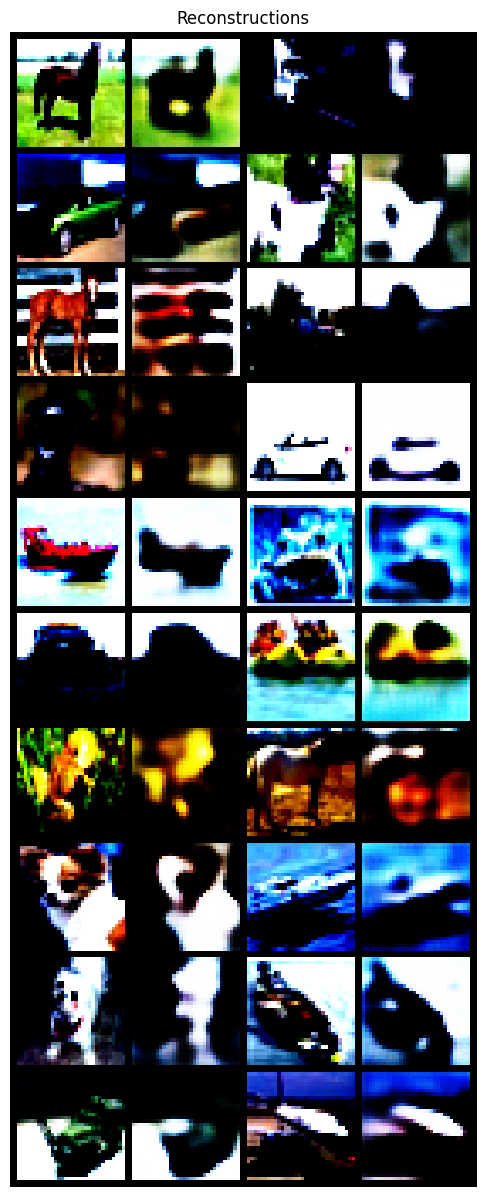

100%|██████████| 351/351 [00:31<00:00, 11.20it/s]


(Epoch 11/[train]) -> Total Loss:	273383.281 -> Reconstruction Loss:	266895.750 -> lr: 0.0009043820750088043


100%|██████████| 40/40 [00:26<00:00,  1.51it/s]


(Epoch 11/[val]) -> Total Loss:	268807.812 -> Reconstruction Loss:	262684.812 -> lr: 0.0009043820750088043


100%|██████████| 351/351 [00:30<00:00, 11.51it/s]


...

(Epoch 19/[val]) -> Total Loss:	267555.594 -> Reconstruction Loss:	261418.406 -> lr: 0.0008345137614500873


100%|██████████| 351/351 [00:30<00:00, 11.62it/s]


(Epoch 20/[train]) -> Total Loss:	272227.469 -> Reconstruction Loss:	265804.156 -> lr: 0.0008261686238355864


100%|██████████| 40/40 [00:25<00:00,  1.55it/s]
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


(Epoch 20/[val]) -> Total Loss:	267601.188 -> Reconstruction Loss:	261368.719 -> lr: 0.0008261686238355864


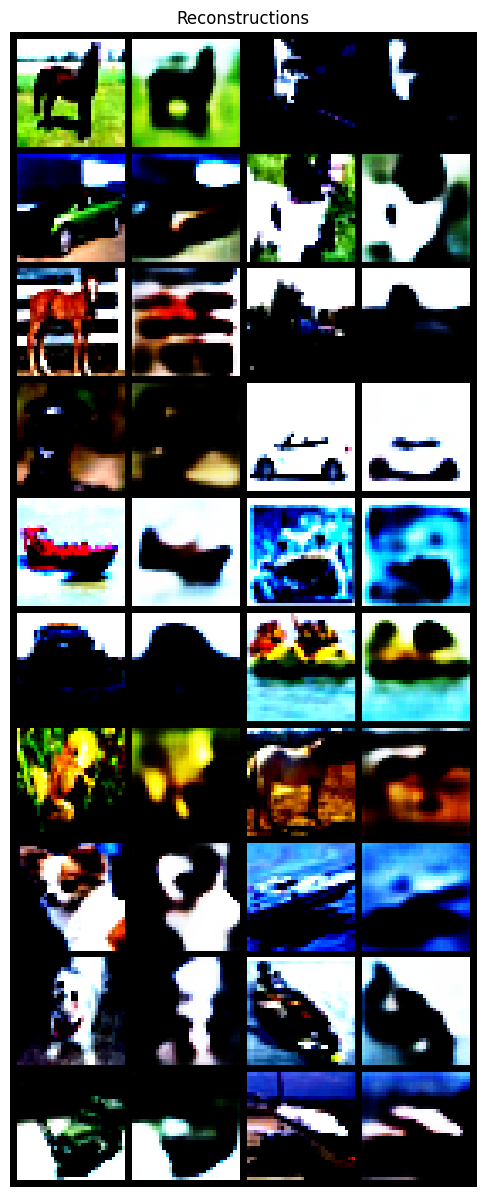

100%|██████████| 351/351 [00:30<00:00, 11.52it/s]


(Epoch 21/[train]) -> Total Loss:	272042.594 -> Reconstruction Loss:	265621.000 -> lr: 0.0008179069375972306


100%|██████████| 40/40 [00:25<00:00,  1.57it/s]


(Epoch 21/[val]) -> Total Loss:	267511.938 -> Reconstruction Loss:	261261.922 -> lr: 0.0008179069375972306


100%|██████████| 351/351 [00:30<00:00, 11.53it/s]


...

(Epoch 29/[val]) -> Total Loss:	267158.344 -> Reconstruction Loss:	260832.469 -> lr: 0.0007547192872036325


100%|██████████| 351/351 [00:30<00:00, 11.62it/s]


(Epoch 30/[train]) -> Total Loss:	271527.531 -> Reconstruction Loss:	265105.781 -> lr: 0.0007471720943315961


100%|██████████| 40/40 [00:25<00:00,  1.56it/s]
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


(Epoch 30/[val]) -> Total Loss:	267114.000 -> Reconstruction Loss:	260898.297 -> lr: 0.0007471720943315961


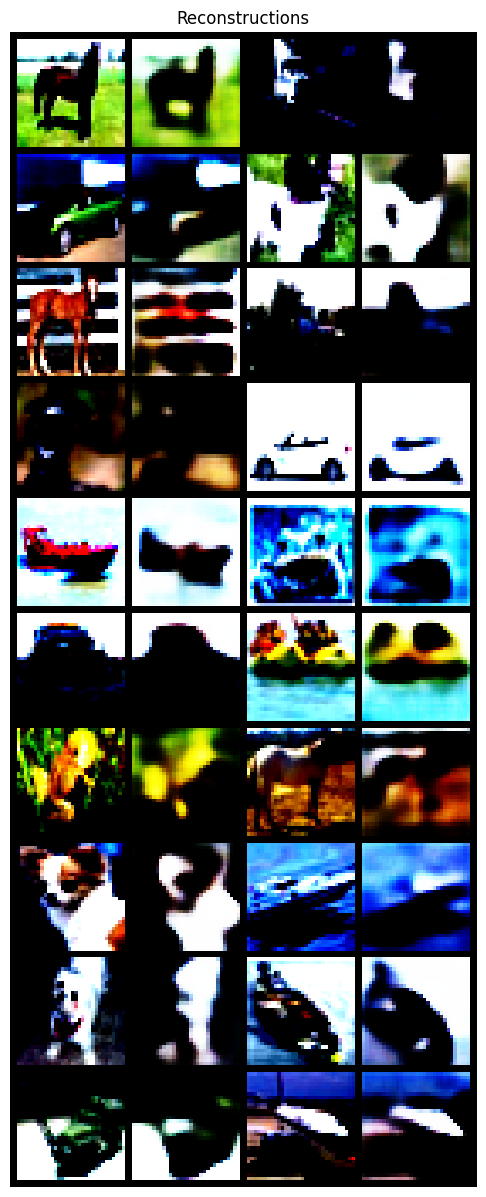

100%|██████████| 351/351 [00:30<00:00, 11.54it/s]


(Epoch 31/[train]) -> Total Loss:	271474.875 -> Reconstruction Loss:	265053.000 -> lr: 0.0007397003733882801


100%|██████████| 40/40 [00:25<00:00,  1.57it/s]


(Epoch 31/[val]) -> Total Loss:	267079.812 -> Reconstruction Loss:	260882.453 -> lr: 0.0007397003733882801


100%|██████████| 351/351 [00:30<00:00, 11.58it/s]


...

(Epoch 39/[val]) -> Total Loss:	266849.594 -> Reconstruction Loss:	260587.750 -> lr: 0.0006825545950103868


100%|██████████| 351/351 [00:30<00:00, 11.38it/s]


(Epoch 40/[train]) -> Total Loss:	271049.344 -> Reconstruction Loss:	264627.500 -> lr: 0.000675729049060283


100%|██████████| 40/40 [00:26<00:00,  1.52it/s]
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


(Epoch 40/[val]) -> Total Loss:	266910.531 -> Reconstruction Loss:	260595.781 -> lr: 0.000675729049060283


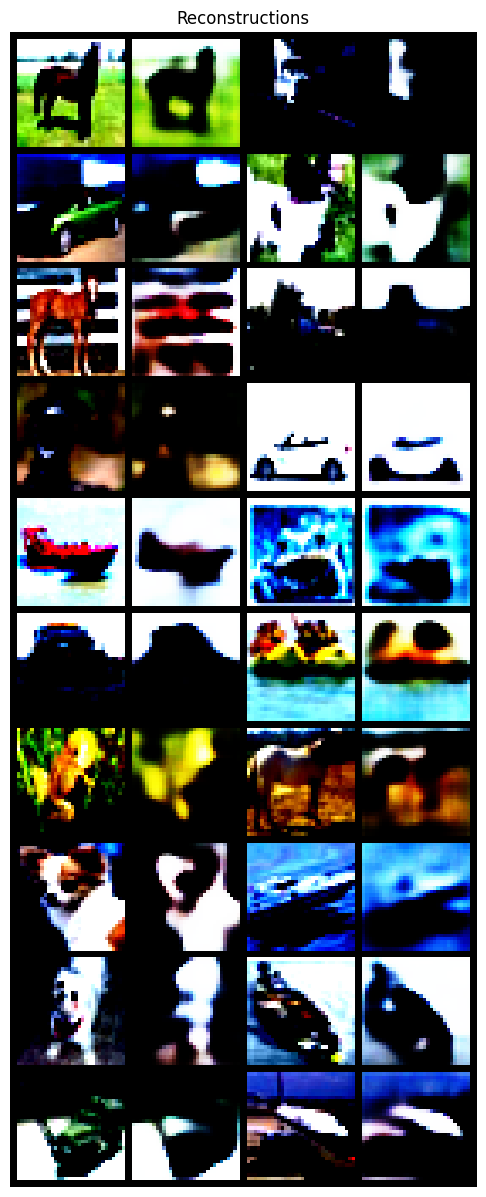

100%|██████████| 351/351 [00:31<00:00, 10.99it/s]


(Epoch 41/[train]) -> Total Loss:	271039.469 -> Reconstruction Loss:	264616.812 -> lr: 0.0006689717585696801


100%|██████████| 40/40 [00:25<00:00,  1.55it/s]


(Epoch 41/[val]) -> Total Loss:	266897.656 -> Reconstruction Loss:	260563.781 -> lr: 0.0006689717585696801


100%|██████████| 351/351 [00:30<00:00, 11.63it/s]


...

(Epoch 49/[val]) -> Total Loss:	266792.781 -> Reconstruction Loss:	260548.969 -> lr: 0.0006172901409422877


100%|██████████| 351/351 [00:31<00:00, 11.32it/s]


(Epoch 50/[train]) -> Total Loss:	270797.281 -> Reconstruction Loss:	264372.000 -> lr: 0.0006111172395328649


100%|██████████| 40/40 [00:25<00:00,  1.55it/s]
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


(Epoch 50/[val]) -> Total Loss:	266840.906 -> Reconstruction Loss:	260508.781 -> lr: 0.0006111172395328649


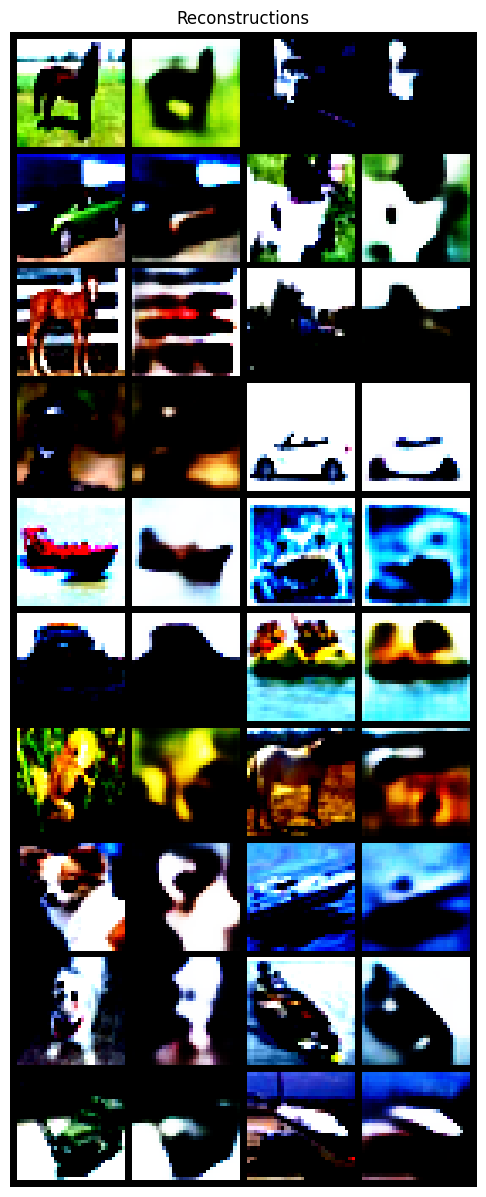

100%|██████████| 351/351 [00:30<00:00, 11.51it/s]


(Epoch 51/[train]) -> Total Loss:	270745.000 -> Reconstruction Loss:	264322.500 -> lr: 0.0006050060671375363


100%|██████████| 40/40 [00:25<00:00,  1.56it/s]


(Epoch 51/[val]) -> Total Loss:	266767.750 -> Reconstruction Loss:	260594.250 -> lr: 0.0006050060671375363


100%|██████████| 351/351 [00:30<00:00, 11.43it/s]


...

(Epoch 59/[val]) -> Total Loss:	266642.812 -> Reconstruction Loss:	260492.344 -> lr: 0.0005582661385478637


100%|██████████| 351/351 [00:30<00:00, 11.59it/s]


(Epoch 60/[train]) -> Total Loss:	270527.281 -> Reconstruction Loss:	264094.688 -> lr: 0.000552683477162385


100%|██████████| 40/40 [00:25<00:00,  1.55it/s]
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


(Epoch 60/[val]) -> Total Loss:	266690.281 -> Reconstruction Loss:	260413.219 -> lr: 0.000552683477162385


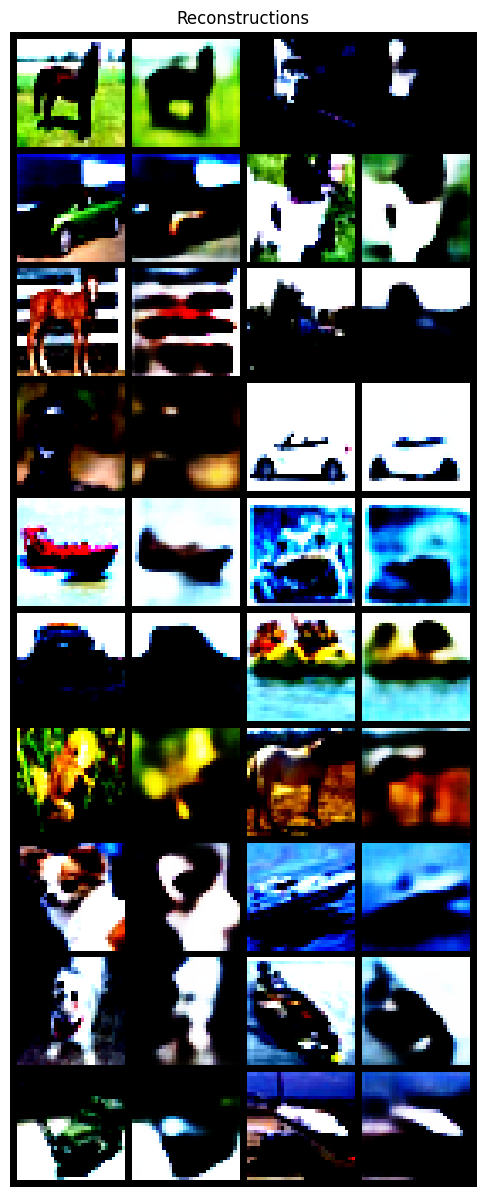

100%|██████████| 351/351 [00:31<00:00, 11.17it/s]


(Epoch 61/[train]) -> Total Loss:	270525.938 -> Reconstruction Loss:	264093.531 -> lr: 0.0005471566423907612


100%|██████████| 40/40 [00:26<00:00,  1.52it/s]


(Epoch 61/[val]) -> Total Loss:	266689.562 -> Reconstruction Loss:	260407.531 -> lr: 0.0005471566423907612


100%|██████████| 351/351 [00:30<00:00, 11.53it/s]


...

(Epoch 69/[val]) -> Total Loss:	266598.750 -> Reconstruction Loss:	260339.281 -> lr: 0.0005048858887870696


100%|██████████| 351/351 [00:30<00:00, 11.62it/s]


(Epoch 70/[train]) -> Total Loss:	270385.062 -> Reconstruction Loss:	263946.406 -> lr: 0.0004998370298991989


100%|██████████| 40/40 [00:25<00:00,  1.56it/s]
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


(Epoch 70/[val]) -> Total Loss:	266634.562 -> Reconstruction Loss:	260338.703 -> lr: 0.0004998370298991989


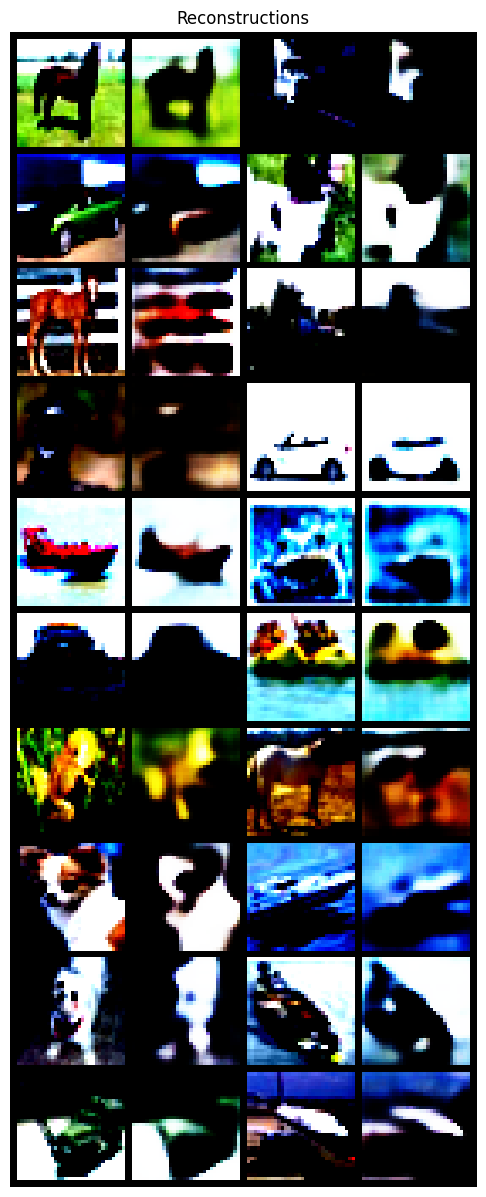

100%|██████████| 351/351 [00:30<00:00, 11.49it/s]


(Epoch 71/[train]) -> Total Loss:	270388.969 -> Reconstruction Loss:	263950.062 -> lr: 0.000494838659600207


100%|██████████| 40/40 [00:25<00:00,  1.57it/s]


(Epoch 71/[val]) -> Total Loss:	266577.375 -> Reconstruction Loss:	260311.094 -> lr: 0.000494838659600207


100%|██████████| 351/351 [00:30<00:00, 11.51it/s]


...

(Epoch 74/[val]) -> Total Loss:	266638.656 -> Reconstruction Loss:	260411.969 -> lr: 0.00048014145657142114


100%|██████████| 351/351 [00:30<00:00, 11.51it/s]


(Epoch 75/[train]) -> Total Loss:	270287.125 -> Reconstruction Loss:	263842.469 -> lr: 0.00047534004200570695


100%|██████████| 40/40 [00:25<00:00,  1.56it/s]

(Epoch 75/[val]) -> Total Loss:	266619.312 -> Reconstruction Loss:	260405.406 -> lr: 0.00047534004200570695


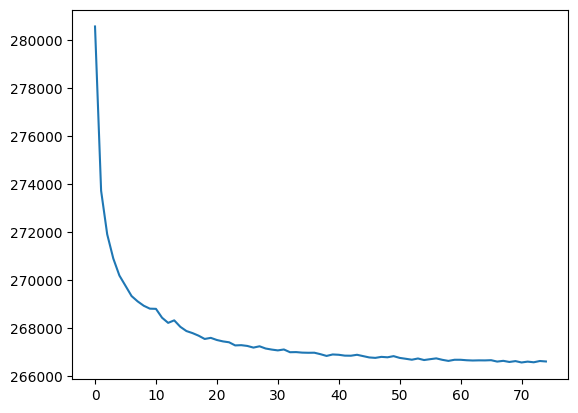

In [ ]:
epochs = 70
warmup_epochs = 50
max_beta = 0.5
# max_beta = 1.0

early_stopping, val_lossses = train_vae(model=vae, loaders=dataloaders, criterion=vae_loss_function, optimizer=optim, lr_scheduler=scheduler, 
                                early_stopping=early_stopping, num_epochs=epochs, warmup_epochs=warmup_epochs, loss_beta=max_beta, device=device)
early_stopping.load_best_model(vae)

plt.plot(val_lossses)

In [ ]:
model_path = "../pretrained_models/vae"

torch.save(vae.state_dict(), f=os.path.join([model_path, "cvae.pth"]))

In [11]:
def visualize_reconstructions(model, input_imgs, labels, device):
    # Reconstruct images
    model.eval()
    with torch.no_grad():
        reconst_imgs, means, log_var = model(input_imgs.to(device), labels.to(device))
    reconst_imgs = reconst_imgs.cpu()
    
    # Plotting
    imgs = torch.stack([input_imgs, reconst_imgs], dim=1).flatten(0,1)
    grid = torchvision.utils.make_grid(imgs, nrow=6, normalize=False)
    grid = grid.permute(1, 2, 0)
    if len(input_imgs) == 6:
        plt.figure(figsize=(15,10))
    else:
        plt.figure(figsize=(15,15))
    plt.title("Reconstructions")
    plt.imshow(grid)
    plt.axis('off')
    plt.show()


def generate_images(model, n_imgs, device):
    # Generate images
    model.eval()
    with torch.no_grad():
        generated_imgs = model.decoder(torch.randn([n_imgs, model.latent_dim]).to(device), torch.randint(0, model.num_classes, (n_imgs,)).to(device))
    generated_imgs = generated_imgs.cpu()
    
    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=False) # produces 'channels first' format
    grid = grid.permute(1, 2, 0)    # matplotplit.imshow takes 'channels' last format
    if len(generated_imgs) == 6:
        plt.figure(figsize=(15,10))
    else:
        plt.figure(figsize=(15,15))
    plt.title("Generations")
    plt.imshow(grid)
    plt.axis('off')
    plt.show()

In [12]:
vae.eval()
with torch.inference_mode():    
    test_losses = []
    for x, y in tqdm(dataloaders["test"]):
        x = x.to(device)
        y = y.to(device)
        x_hat, mean, logvar = vae(x, y)
        total_loss, _ = vae_loss_function(x, x_hat, mean, logvar)
        test_losses.append(total_loss.item())
    print(f"Mean test loss: {np.mean(np.array(test_losses))}")

100%|██████████| 79/79 [00:25<00:00,  3.10it/s]

Mean test loss: 265350.42859968357


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


torch.Size([27, 3, 32, 32])
torch.Size([27])


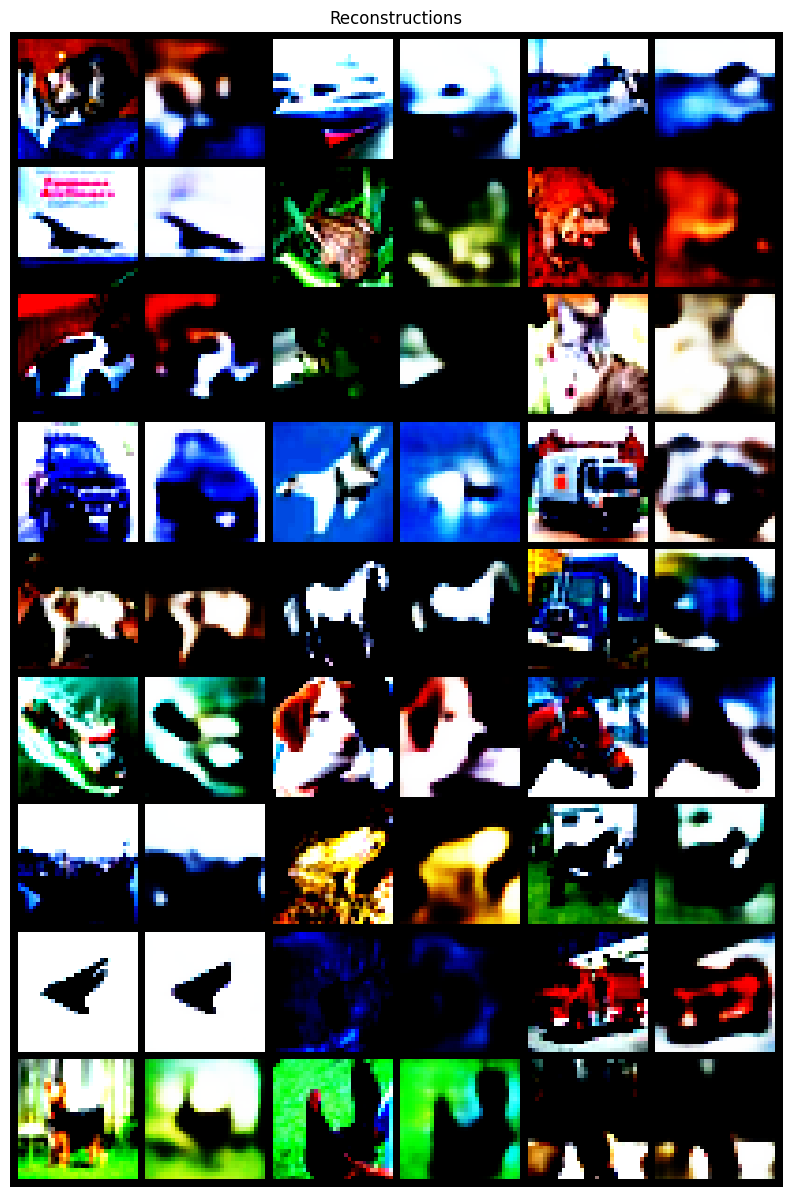

In [13]:
n_samples = 27
sample_imgs = torch.stack([dataloaders["test"].dataset[i][0] for i in range(n_samples)], dim=0)    # wraps all tensors in one one external tensor - [[..], [..], .., [..]]
sample_lables = torch.tensor([dataloaders["test"].dataset[i][1] for i in range(n_samples)])
print(sample_imgs.shape)
print(sample_lables.shape)
visualize_reconstructions(vae, input_imgs=sample_imgs, labels=sample_lables, device=device)

### Generations form noise

In [ ]:
num_samples = 100

vae.eval()
with torch.no_grad():
    fixed_noise = torch.randn(num_samples, latent_dim, device=device)
    rnd_labels = torch.randint(0, len(classes), size=(num_samples,), device=device)
    generations_vae = vae.decoder(fixed_noise, rnd_labels)
    

In [ ]:
grid = torchvision.utils.make_grid(generations_vae.cpu()[:20], nrow=4, normalize=False) # produces 'channels first' format
grid = grid.permute(1, 2, 0)    # matplotplit.imshow takes 'channels' last format
if len(generations_vae) == 4:
    plt.figure(figsize=(15,10))
else:
    plt.figure(figsize=(15,15))
plt.title("Generations from noise")
plt.imshow(grid)
plt.axis('off')
plt.show()